# 2.01 · MiBici baselines: seasonal naive and historical average

**Phase 2 (model building)** following the [Cookiecutter Data Science](https://cookiecutter-data-science.drivendata.org/using-the-template/) convention: `PHASE.NOTEBOOK-initials-description`. It runs after `1.04` and `1.05` because it reads their outputs.

- **Input:** `data/processed/mibici/features/station_hour_features.parquet` (notebook `1.04`) and `station_profiles.parquet` (notebook `1.05`).
- **Output:** one MLflow run per baseline and target in the `mibici` experiment, each with its metrics, input datasets and fitted model.

**Why.** The [ML Canvas](../references/ml-canvas.md) sets two simple rules as the *baselines the model must beat*: the same station and hour one week earlier (seasonal naive), and the mean per station, weekday and hour (historical average). A model only counts as a success if its peak-hour WAPE is at least 10% lower than the best baseline's, so the baselines are trained, tracked and scored before any ML model, on the same split and with the same metrics (`modeling/evaluate.py`).

1. Train both baselines for both targets and track every run.
2. Check that the runs read the exact tables the feature and profile steps wrote.
3. Compare the baselines overall, at peak hours and per station segment.
4. Score the decision metric: flagging the high-imbalance station-days.
5. Look at the forecasts of a few stations against the actual demand.
6. Check that the logged model reproduces the forecasts.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import gc
import os

os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"  # keep the outputs readable

import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd

from team2_mlops2026 import plots
from team2_mlops2026.config import MLFLOW_EXPERIMENT_NAME, MLFLOW_TRACKING_URI
from team2_mlops2026.features import RUN_NAME as FEATURES_RUN
from team2_mlops2026.features import SEED, STATION, TARGETS, TIME
from team2_mlops2026.modeling.evaluate import imbalance_scores
from team2_mlops2026.modeling.models import BASELINES
from team2_mlops2026.modeling.train import (
    MODEL_ARTIFACT,
    load_training_data,
    model_inputs,
    train_tracked,
)
from team2_mlops2026.station_profiles import RUN_NAME as PROFILES_RUN
from team2_mlops2026.tracking import input_digests

pd.set_option("display.max_columns", 50)
plots.use_style()

C:\MLOpsRepos\Proyecto\team2_mlops2026\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-11-05 21:18:50.222 | INFO     | team2_mlops2026.config:<module>:12 - PROJ_ROOT path is: C:\MLOpsRepos\Proyecto\team2_mlops2026


## Parameters

The test split starts at `TEST_START` (2025-10), the month where the test period of `1.04` and the PCA fit of `1.05` end. It runs to the end of the data (2026-09). The 12-fold rolling backtest comes in `2.04`.

In [3]:
PLOT_WEEK = "2026-09-07"  # a Monday in the last test month
NEW_SINCE = "2026-05"  # the stations opened from May 2026 on (notebook 1.05)
NEW_STATION_WEEKS = 2  # shown from the opening hour: the first week has no week-earlier demand

## 1. Train and track

`train_tracked()` loads the features with the profile scores, splits them at `TEST_START`, and fits every baseline for every target. Each model × target is one MLflow run (`train-<model>-<target>`) with:
- the feature and profile tables as input datasets, each with a digest
- the model's params, the tags `model_family`, `target` and `git_commit`
- the `segment_report` metrics (`overall_wape`, `peak_mae`, `top_50_wape`, `group_1_wape`...)
- the fitted model with a signature and an input example

In [4]:
results = train_tracked()
print(f"Experiment '{MLFLOW_EXPERIMENT_NAME}' ({MLFLOW_TRACKING_URI})")
pd.DataFrame(
    [(r.name, r.target, r.run_id) for r in results], columns=["model", "target", "mlflow_run_id"]
)

2026-11-05 21:19:02.373 | SUCCESS  | team2_mlops2026.modeling.train:train_model:100 - seasonal_naive for departures: WAPE 0.749 overall, 0.649 at peak hours


🏃 View run train-seasonal_naive-departures at: http://127.0.0.1:5001/#/experiments/1/runs/9a622e2ad4af4be2b0b0a0d225adbc8e
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


2026-11-05 21:21:17.336 | SUCCESS  | team2_mlops2026.modeling.train:train_model:100 - seasonal_naive for arrivals: WAPE 0.721 overall, 0.600 at peak hours


🏃 View run train-seasonal_naive-arrivals at: http://127.0.0.1:5001/#/experiments/1/runs/1dde8a36c52d4e11a94623b04b194b63
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


2026-11-05 21:21:27.400 | SUCCESS  | team2_mlops2026.modeling.train:train_model:100 - historical_average for departures: WAPE 0.716 overall, 0.657 at peak hours


🏃 View run train-historical_average-departures at: http://127.0.0.1:5001/#/experiments/1/runs/cb9ac1b3b74e4a27a95006875db2b349
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


2026-11-05 21:21:37.757 | SUCCESS  | team2_mlops2026.modeling.train:train_model:100 - historical_average for arrivals: WAPE 0.695 overall, 0.613 at peak hours


🏃 View run train-historical_average-arrivals at: http://127.0.0.1:5001/#/experiments/1/runs/a5867f63818647a797bab918ef2693f0
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
Experiment 'mibici' (http://127.0.0.1:5001)


,model,target,mlflow_run_id
0,seasonal_naive,departures,9a622e2ad4af4be2b0b0a0d225adbc8e
1,seasonal_naive,arrivals,1dde8a36c52d4e11a94623b04b194b63
2,historical_average,departures,cb9ac1b3b74e4a27a95006875db2b349
3,historical_average,arrivals,a5867f63818647a797bab918ef2693f0


## 2. Lineage: the runs read the tables the pipeline wrote

The latest `build-station-hour-features` and `fit-station-profiles` runs log the digests of the tables they wrote. Every training run must log the same digests.

In [5]:
upstream = {}
for run_name in (FEATURES_RUN, PROFILES_RUN):
    latest = mlflow.search_runs(
        experiment_names=[MLFLOW_EXPERIMENT_NAME],
        filter_string=f"tags.mlflow.runName = '{run_name}' and status = 'FINISHED'",
        order_by=["start_time DESC"],
        max_results=1,
        output_format="list",
    )[0]
    upstream |= input_digests(latest.info.run_id)

lineage = pd.DataFrame({f"{r.name} / {r.target}": input_digests(r.run_id) for r in results})
lineage["pipeline output"] = pd.Series(upstream)
assert lineage.eq(lineage["pipeline output"], axis=0).all().all()
lineage

,seasonal_naive / departures,seasonal_naive / arrivals,historical_average / departures,historical_average / arrivals,pipeline output
mibici_station_hour_features,16431f983b9f4f724785b28c12b6bbe0,16431f983b9f4f724785b28c12b6bbe0,16431f983b9f4f724785b28c12b6bbe0,16431f983b9f4f724785b28c12b6bbe0,16431f983b9f4f724785b28c12b6bbe0
mibici_station_profiles,b934c6e9cdfd64656cedb121497da9c0,b934c6e9cdfd64656cedb121497da9c0,b934c6e9cdfd64656cedb121497da9c0,b934c6e9cdfd64656cedb121497da9c0,b934c6e9cdfd64656cedb121497da9c0


**Result → action.** All four runs read the feature table and the station profiles with the same digests as the outputs of the latest `build-station-hour-features` and `fit-station-profiles` runs. The tracked lineage now runs from the raw CSVs to the trained models, and each run can be traced to the exact data it was trained on.

## 3. The bar for the ML models

WAPE (total absolute error / total demand) and MAE on the test split, overall and at weekday peak hours (7-9 h and 17-19 h).

In [6]:
reports = pd.concat({(r.name, r.target): r.report for r in results}, names=["model", "target"])
bar = reports.loc[pd.IndexSlice[:, :, ["overall", "peak"]], ["wape", "mae"]].unstack("segment")
bar.round(3)

wape            mae       
segment                       overall   peak overall   peak
model              target                                  
historical_average arrivals     0.695  0.613   0.843  1.472
                   departures   0.716  0.657   0.869  1.578
seasonal_naive     arrivals     0.721  0.600   0.874  1.441
                   departures   0.749  0.649   0.909  1.557

In [7]:
best = reports.xs("peak", level="segment")["wape"].unstack("model").idxmin(axis=1)
print("Best baseline at peak hours:", best.to_dict())
reports["wape"].unstack("model").unstack("target").round(3)

Best baseline at peak hours: {'arrivals': 'seasonal_naive', 'departures': 'seasonal_naive'}


model           historical_average            seasonal_naive           
target                    arrivals departures       arrivals departures
segment                                                                
overall                      0.695      0.716          0.721      0.749
peak                         0.613      0.657          0.600      0.649
top_50                       0.486      0.502          0.533      0.557
group_1                      1.371      1.254          1.296      1.245
group_2                      1.002      1.005          1.048      1.067
group_3                      0.767      0.780          0.863      0.884
group_4                      0.652      0.679          0.728      0.753
group_5                      0.503      0.525          0.562      0.588
unseen_stations              2.954      2.735          1.232      1.220

**Result → action.**
- **Overall**, the historical average is better for both targets (WAPE 0.716 vs 0.749 for departures, 0.695 vs 0.721 for arrivals). **At peak hours**, the seasonal naive is slightly better (0.649 vs 0.657 and 0.600 vs 0.613). A WAPE around 0.7 means the hourly error is about 70% of the hourly demand: a single station-hour is a small and noisy count.
- The **best baseline** in the success criterion is therefore the **seasonal naive** for both targets. An ML model succeeds with a peak-hour WAPE of at most **0.584 for departures and 0.540 for arrivals** (10% lower), and with no demand group worse than the seasonal naive.
- **By segment**, the historical average is better at the busy stations (top-50 WAPE 0.502 vs 0.557 for departures) and in demand groups 2-5. The seasonal naive is better at the quietest stations (group 1) and far better at the **unseen stations** (1.22 vs 2.74 for departures). The historical average gives those stations the mean of all stations, every hour, while the seasonal naive switches to the station's own demand after its first week.
- WAPE grows as demand drops (from about 0.5 in group 5 to about 1.25 in group 1). In the quietest stations most hours have zero or one trip, so any error is large relative to the demand.

→ The ML models of `2.02` need both signals: the recent lags (the seasonal naive's strength, especially for new stations) and a smooth station × weekday × hour level (the historical average's strength at busy stations).

## 4. Decision metric: high-imbalance station-days

A station-day is *high-imbalance* when its absolute net flow (arrivals − departures) exceeds half of its capacity. Precision and recall show how well the forecast departures and arrivals flag the actual ones.

In [8]:
train, test = load_training_data()
X_test = model_inputs(test)
predictions = {(r.name, r.target): r.estimator.predict(X_test) for r in results}
pd.DataFrame(
    {
        name: imbalance_scores(test, predictions[name, "departures"], predictions[name, "arrivals"])
        for name in BASELINES
    }
).T.round(3)

,imbalance_days,flagged_days,imbalance_precision,imbalance_recall
seasonal_naive,23294.0,23449.0,0.479,0.482
historical_average,23294.0,19295.0,0.544,0.451


**Result → action.** The test split holds 23,294 high-imbalance station-days. Both baselines flag about half of them correctly. The seasonal naive flags about as many days as there are (23,449, precision 0.48, recall 0.48). The historical average flags fewer (19,295) and is more precise but finds fewer of them (0.54 and 0.45), because averaging smooths out the extreme days. This is the decision-metric bar: a useful model should raise both precision and recall.

## 5. Station forecasts against the actual demand

The busiest station of the training period in one week of September 2026, and the busiest station opened since May 2026 in its first two weeks. In its first week the seasonal naive has no week-earlier hour and uses the historical average, which for an unseen station is the mean of all stations.

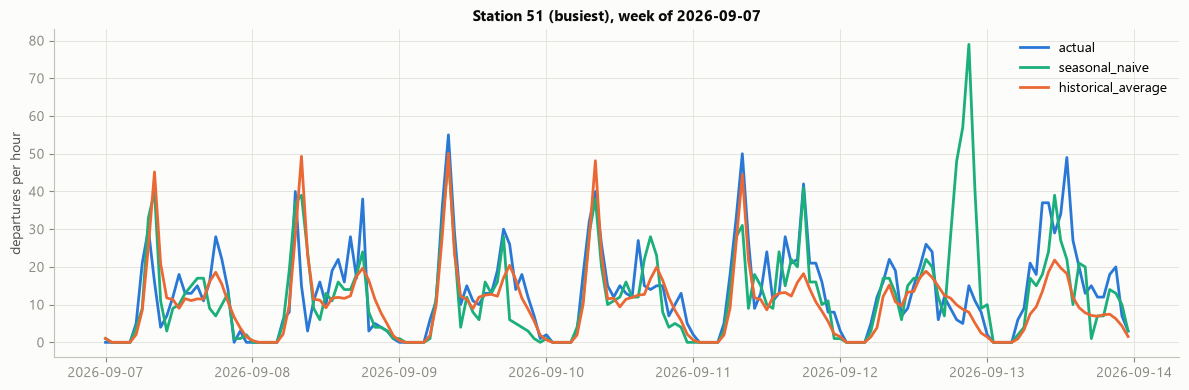

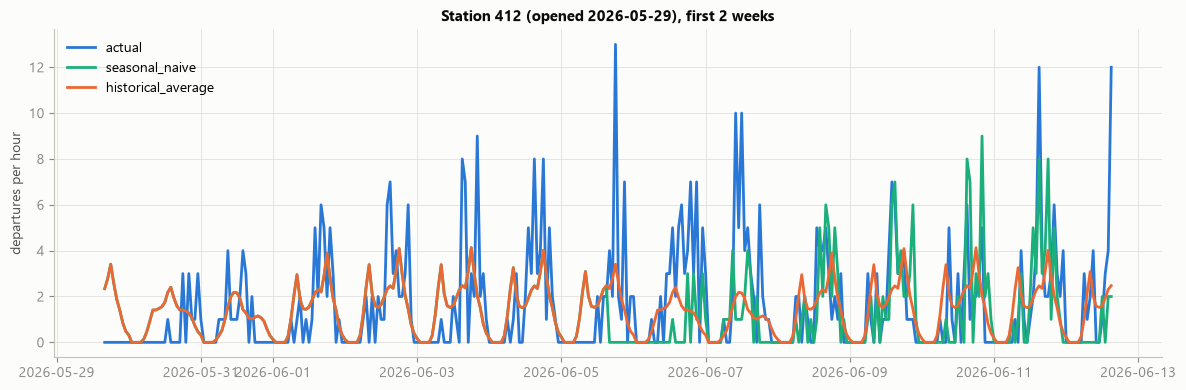

In [9]:
opened = test.groupby(STATION)[TIME].min()
busiest = train.groupby(STATION)["departures"].mean().idxmax()
new = test[test[STATION].isin(opened[opened >= NEW_SINCE].index)]
newest = new.groupby(STATION)["departures"].sum().idxmax()
del train, new
gc.collect()

windows = {
    f"Station {busiest} (busiest), week of {PLOT_WEEK}": (busiest, pd.Timestamp(PLOT_WEEK), 1),
    f"Station {newest} (opened {opened[newest]:%Y-%m-%d}), first {NEW_STATION_WEEKS} weeks": (
        newest,
        opened[newest],
        NEW_STATION_WEEKS,
    ),
}
for title, (station, start, weeks) in windows.items():
    rows = (
        (test[STATION] == station)
        & (test[TIME] >= start)
        & (test[TIME] < start + pd.Timedelta(weeks=weeks))
    ).to_numpy()
    forecasts = pd.DataFrame(
        {
            "actual": test.loc[rows, "departures"].to_numpy(),
            **{name: predictions[name, "departures"][rows] for name in BASELINES},
        },
        index=test.loc[rows, TIME],
    )
    plots.plot_lines(forecasts, title, "departures per hour")

**Result → action.**
- **Busy station:** both baselines follow the commuter shape. The seasonal naive copies last week's one-off events, such as the Saturday-evening spike of up to 79 departures that did not repeat on 2026-09-12. The historical average does not chase single events, but it flattens the evening peaks and underestimates some of them.
- **New station:** in its first week both baselines predict the all-station mean (no week-earlier hour and no training history). From the second week on, the seasonal naive follows the station's own pattern, while the historical average keeps the all-station mean for the whole test period. That explains its WAPE of 2.7 on the unseen stations.

## 6. The logged model reproduces the forecasts

The model artifact of each run is what later stages load (Model Registry, batch predictions), so it must give the same forecasts as the estimator trained here.

In [10]:
sample = X_test.sample(10_000, random_state=SEED)
for r in results:
    logged = mlflow.sklearn.load_model(f"runs:/{r.run_id}/{MODEL_ARTIFACT}")
    assert np.allclose(logged.predict(sample), r.estimator.predict(sample))
print(f"{len(results)} logged models reproduce the forecasts on {len(sample):,} test hours")

4 logged models reproduce the forecasts on 10,000 test hours


## Findings and next steps

**Output**
- Four MLflow runs in the `mibici` experiment (`train-<model>-<target>`), one per baseline and target. Each has its params, the segment metrics, the tags `model_family`, `target` and `git_commit`, the feature and profile tables as input datasets, and the fitted model with a signature and an input example. `python -m team2_mlops2026.modeling.train fit --model seasonal_naive --model historical_average` reproduces them in about a minute.
- The model artifacts are saved in the skops format, which does not run arbitrary code on load (MLflow's default). The two baseline classes are listed as trusted types.

**The bar for the ML models (test split 2025-10 to 2026-09)**

| Target | Best baseline (peak) | Peak WAPE | Success: peak WAPE at most | Overall WAPE (best) | Peak MAE (best) |
|---|---|---|---|---|---|
| departures | seasonal naive | 0.649 | 0.584 | 0.716 (historical average) | 1.557 |
| arrivals | seasonal naive | 0.600 | 0.540 | 0.695 (historical average) | 1.441 |

**Implications for the next stages**
- *Model comparison (`2.02`):* the candidates must combine the lags with a stable station-hour level. They must also do better than the all-station mean for unseen stations. The target encoding cannot help there, and the PCA profile scores (`1.05`) exist only for the stations profiled before 2025-10, so `2.02` checks what the lags, location and capacity achieve for the stations opened later.
- *Low-demand stations:* their WAPE is above 1 for both baselines. The fairness condition (no demand group worse than the best baseline) is most at risk there, so `2.02` must check it. (`2.02` shows that in group 1 the hourly WAPE is lowest for a forecast of zero, so the check compares the groups on the WAPE of station-day totals.)
- *Backtest (`2.04`):* these numbers come from a single 12-month test split. The 12-fold rolling backtest will show how stable the gap between the baselines is from month to month.